# PE-SFCC Detection Analysis — Normal vs Dysarthric Speech (UASpeech)

Implements and evaluates the **Perceptually Enhanced Single Frequency Cepstral Coefficients** from:
> Gurugubelli, K. & Vuppala, A. K., *"Perceptually Enhanced Single Frequency Filtering for Dysarthric Speech Detection and Intelligibility Assessment"*, ICASSP 2019.

| Setting | Value |
|---|---|
| Features | 39-dim PE-SFCC (13 coefficients + delta + delta-delta, mean-pooled) |
| Classifier | SVM — RBF kernel, C=1, γ = 1/(D·Var(X)) |
| Evaluation | LOSO (Leave-One-Speaker-Out), 28 folds |
| Microphone | M6 |
| Input SR | 16 kHz (resampled to 8 kHz for PE-SFCC, matching paper) |
| SFF pole radius | a = 0.9875 |
| SFF range | 100–4000 Hz, 20 Hz resolution → M = 196 bands |
| Mel bands | 26 |
| Cepstral dim | 13 |
| Frame shift | 5 ms (40 samples at 8 kHz) |

Paper uses an i-vector + PLDA classifier.  
We use RBF-SVM + LOSO to match the MFCC/wav2vec2 setup in this project.

## 1.  Imports & Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import librosa
import scipy.signal
from tqdm.notebook import tqdm
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report,
)
import pandas as pd

plt.rcParams.update({"figure.dpi": 120})
print("Ready.")

Ready.


## 2.  PE-SFCC Implementation

**Pipeline:**
1. Resample to 8 kHz
2. **Pre-emphasis** — `y[n] = y[n] − 0.97·y[n−1]` (paper Section 2.2 Step 1)
3. **SFF filterbank** — 196 complex 1-pole IIR filters: `H_k(z) = 1 / (1 − a_k·z⁻¹)`, `a_k = a·exp(−jω_k)`
4. Subsample at 5 ms hop → instantaneous amplitude matrix `S(k, t)`, shape `(196, T)`
5. **Mel warping** — triangular Mel filterbank → `(26, T)`
6. **Equal-loudness pre-emphasis** — Hermansky (1990) / Terhardt weighting per Mel band
7. **Power-law compression** — `S^(1/5)`
8. **log**
9. **IFFT** along frequency axis → take first 13 coefficients → `(13, T)`

In [2]:
def _hz_to_mel(f):
    return 2595.0 * np.log10(1.0 + np.asarray(f, dtype=float) / 700.0)

def _mel_to_hz(m):
    return 700.0 * (10.0 ** (np.asarray(m, dtype=float) / 2595.0) - 1.0)


def _mel_filterbank(sff_freqs, n_mel, fmin, fmax):
    """
    Triangular Mel filterbank matrix W of shape (n_mel, M).
    Maps SFF frequency axis (M bins) → n_mel Mel bands.
    """
    mel_points = np.linspace(_hz_to_mel(fmin), _hz_to_mel(fmax), n_mel + 2)
    hz_points  = _mel_to_hz(mel_points)   # (n_mel+2,)
    M = len(sff_freqs)
    W = np.zeros((n_mel, M))
    for m in range(n_mel):
        fl, fc, fr = hz_points[m], hz_points[m + 1], hz_points[m + 2]
        for k, f in enumerate(sff_freqs):
            if fl <= f < fc:
                W[m, k] = (f - fl) / (fc - fl)
            elif fc <= f <= fr:
                W[m, k] = (fr - f) / (fr - fc)
    return W


def _mel_centers(n_mel, fmin, fmax):
    """Centre frequencies (Hz) of each Mel band."""
    mel_points = np.linspace(_hz_to_mel(fmin), _hz_to_mel(fmax), n_mel + 2)
    return _mel_to_hz(mel_points[1:-1])


def _equal_loudness_weights(freqs_hz):
    """
    Equal-loudness pre-emphasis curve (Terhardt 1979 approximation).
    Returns normalised weights (max = 1) per frequency.
    """
    f  = np.asarray(freqs_hz, dtype=float)
    f2 = f ** 2
    W  = ((f2 + 1.44e6) * f ** 4) / ((f2 + 1.6e5) ** 2 * (f2 + 9.61e6) + 1e-30)
    W  = W / (W.max() + 1e-30)
    return W


def _sff_amplitude(y, a_k_all, hop):
    """
    Vectorised SFF: filter y through all M complex 1-pole IIR filters
    and return the instantaneous amplitude at every hop-th sample.

    Uses frame-level batch update to avoid a Python loop over every sample:
        state_new = a_k^hop * state_old + (powers @ frame)
    where powers[k, i] = a_k^(hop-1-i).

    Returns S of shape (M, n_frames).
    """
    N       = len(y)
    M       = len(a_k_all)
    n_frames = (N + hop - 1) // hop

    # (M, hop): powers[k, i] = a_k^(hop-1-i)
    exp_arr = np.arange(hop - 1, -1, -1)        # [hop-1 .. 0]
    powers  = a_k_all[:, None] ** exp_arr        # (M, hop)  complex
    a_k_hop = a_k_all ** hop                     # (M,)

    S     = np.zeros((M, n_frames))
    state = np.zeros(M, dtype=complex)

    for t in range(n_frames):
        start = t * hop
        end   = min(start + hop, N)
        frame = np.zeros(hop)
        frame[: end - start] = y[start:end]
        state    = a_k_hop * state + (powers @ frame)   # (M,)
        S[:, t]  = np.abs(state)

    return S

print("Helper functions defined.")

Helper functions defined.


In [ ]:
TARGET_SR  = 8000    # paper uses 8 kHz
SFF_A      = 0.9875   # pole radius
FREQ_START = 100
FREQ_END   = 4000
FREQ_RES   = 20       # 20 Hz resolution → M = 196 bands
N_MEL      = 26
N_CEP      = 13
HOP_MS     = 5.0      # 5ms hop

SFF_FREQS = np.arange(FREQ_START, FREQ_END + FREQ_RES, FREQ_RES)  # (196,)
M_BANDS   = len(SFF_FREQS)
HOP_SAMPS = int(TARGET_SR * HOP_MS / 1000)   # 40 samples

OMEGAS  = 2 * np.pi * SFF_FREQS / TARGET_SR
A_K_ALL = SFF_A * np.exp(-1j * OMEGAS)       # (196,) complex poles

MEL_W      = _mel_filterbank(SFF_FREQS, N_MEL, FREQ_START, FREQ_END)  # (26, 196)
MEL_CTRS   = _mel_centers(N_MEL, FREQ_START, FREQ_END)                 # (26,)
ELC_W      = _equal_loudness_weights(MEL_CTRS)                         # (26,)

print(f"SFF bands : {M_BANDS}  ({FREQ_START}–{FREQ_END} Hz, {FREQ_RES} Hz step)")
print(f"Mel bands : {N_MEL}")
print(f"Hop (samp): {HOP_SAMPS}  ({HOP_MS} ms @ {TARGET_SR} Hz)")
print(f"Cepstral  : {N_CEP}")


def compute_pe_sfcc(y, sr):
    """
    Full PE-SFCC pipeline for a single utterance.
    Returns cepstral matrix of shape (N_CEP, n_frames).
    """
    # Resample to 8 kHz
    if sr != TARGET_SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=TARGET_SR)
    # Pre-emphasis
    y = np.append(y[0], y[1:] - 0.97 * y[:-1])
    # SFF filterbank → instantaneous amplitude at every hop
    S = _sff_amplitude(y, A_K_ALL, HOP_SAMPS)   # (196, T)
    # Mel warping
    S_mel = MEL_W @ S                             # (26, T)
    # Equal-loudness pre-emphasis
    S_mel = S_mel * ELC_W[:, None]
    # Power-law compression (1/5 power)
    S_comp = np.power(np.maximum(S_mel, 1e-10), 0.2)
    # log
    S_log = np.log(S_comp)
    # IFFT along frequency axis → first N_CEP coefficients
    cep = np.real(np.fft.ifft(S_log, axis=0))[:N_CEP, :]  # (13, T)
    return cep

print("\ncompute_pe_sfcc() ready.")

SFF bands : 196  (100–4000 Hz, 20 Hz step)
Mel bands : 26
Hop (samp): 40  (5.0 ms @ 8000 Hz)
Cepstral  : 13

compute_pe_sfcc() ready.


### 2b.  Sanity-check on a sample file

Verify shape and absence of NaN/Inf before running the full dataset.

File      : CF02_B1_C10_M6.wav
Duration  : 1.85s  @ 16000 Hz
Cep shape : (13, 370)  (13 coeffs × T frames)
NaN/Inf   : False
Value range: [-1.5797, 0.0322]


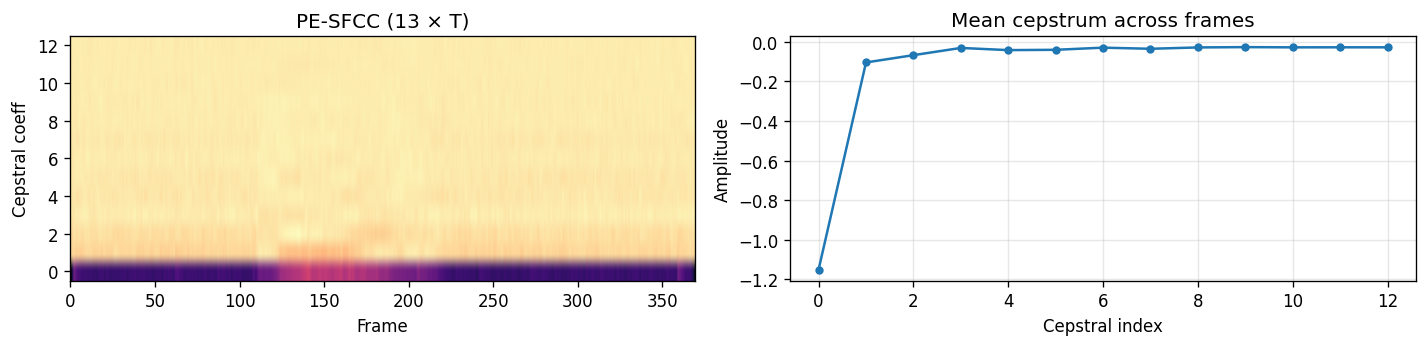

In [ ]:
_test_spk_dir = os.path.join("UASpeech", "UASpeech_C", "audio", "original")
_spk0 = sorted(os.listdir(_test_spk_dir))[0]
_wavs = sorted(f for f in os.listdir(os.path.join(_test_spk_dir, _spk0))
               if f.endswith("_M6.wav"))
_fpath = os.path.join(_test_spk_dir, _spk0, _wavs[0])

_y, _sr = librosa.load(_fpath, sr=16_000, mono=True)
_cep    = compute_pe_sfcc(_y, _sr)

print(f"File      : {_wavs[0]}")
print(f"Duration  : {len(_y)/_sr:.2f}s  @ {_sr} Hz")
print(f"Cep shape : {_cep.shape}  (13 coeffs × T frames)")
print(f"NaN/Inf   : {np.isnan(_cep).any() or np.isinf(_cep).any()}")
print(f"Value range: [{_cep.min():.4f}, {_cep.max():.4f}]")

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].imshow(_cep, aspect="auto", origin="lower", cmap="magma")
axes[0].set_title("PE-SFCC (13 × T)")
axes[0].set_xlabel("Frame")
axes[0].set_ylabel("Cepstral coeff")
axes[1].plot(np.mean(_cep, axis=1), marker="o", ms=4)
axes[1].set_title("Mean cepstrum across frames")
axes[1].set_xlabel("Cepstral index")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3.  Extract PE-SFCC Features

For each utterance:
1. Load M6 wav at 16 kHz, resample to 8 kHz internally
2. Compute PE-SFCC cepstral matrix (13 × T)
3. Compute Δ and ΔΔ (librosa)
4. Mean-pool all three over frames → 39-dim vector

Results are cached to `pe_sfcc_features_uaspeech.npz`.

In [5]:
UA_ROOT = "UASpeech"
SOURCES = [
    (os.path.join(UA_ROOT, "UASpeech_C",  "audio", "original"), 0),  # control
    (os.path.join(UA_ROOT, "UASpeech_FM", "audio", "original"), 1),  # dysarthric
]
MIC        = "M6"
SR_LOAD    = 16_000
MIN_FRAMES = 3
CACHE      = "cache_files/pe_sfcc_features_uaspeech.npz"

os.makedirs("cache_files", exist_ok=True)
if os.path.exists(CACHE):
    print("Loading from cache...")
    data        = np.load(CACHE, allow_pickle=True)
    X           = data["X"]
    y_all       = data["labels"]
    speaker_ids = data["speaker_ids"].tolist()
    print(f"Loaded: {X.shape[0]} samples, {X.shape[1]} dims")
    print(f"Speakers: {sorted(set(speaker_ids))}")
else:
    feats, labels, speaker_ids = [], [], []
    n_skipped = 0

    for folder_root, label in SOURCES:
        for spk in tqdm(sorted(os.listdir(folder_root)),
                        desc=("control" if label == 0 else "dysarthric")):
            spk_path = os.path.join(folder_root, spk)
            if not os.path.isdir(spk_path):
                continue
            wav_files = sorted(
                f for f in os.listdir(spk_path)
                if f.endswith(f"_{MIC}.wav")
            )
            for fname in tqdm(wav_files, desc=spk, leave=False):
                fpath   = os.path.join(spk_path, fname)
                speaker = fname.split("_")[0]
                try:
                    y, _ = librosa.load(fpath, sr=SR_LOAD, mono=True)
                    cep  = compute_pe_sfcc(y, SR_LOAD)   # (13, T)
                    if cep.shape[1] < MIN_FRAMES:
                        n_skipped += 1
                        continue
                    w = min(9, cep.shape[1])
                    if w % 2 == 0:
                        w -= 1
                    delta  = librosa.feature.delta(cep, width=w)
                    delta2 = librosa.feature.delta(cep, order=2, width=w)
                    vec = np.concatenate([
                        np.mean(cep,    axis=1),
                        np.mean(delta,  axis=1),
                        np.mean(delta2, axis=1),
                    ])  # (39,)
                    feats.append(vec)
                    labels.append(label)
                    speaker_ids.append(speaker)
                except Exception as e:
                    print(f"Skipped {fname}: {e}")
                    n_skipped += 1

    X     = np.array(feats)
    y_all = np.array(labels)
    np.savez(CACHE,
             X=X, labels=y_all,
             speaker_ids=np.array(speaker_ids, dtype=object))
    print(f"Saved to {CACHE}  |  shape: {X.shape}")
    print(f"Speakers: {sorted(set(speaker_ids))}")
    print(f"Normal: {(y_all==0).sum()}  Dysarthric: {(y_all==1).sum()}")
    if n_skipped:
        print(f"Skipped: {n_skipped} files")

control:   0%|          | 0/13 [00:00<?, ?it/s]

CF02:   0%|          | 0/765 [00:00<?, ?it/s]

CF03:   0%|          | 0/765 [00:00<?, ?it/s]

CF04:   0%|          | 0/765 [00:00<?, ?it/s]

CF05:   0%|          | 0/765 [00:00<?, ?it/s]

...

M11:   0%|          | 0/765 [00:00<?, ?it/s]

M12:   0%|          | 0/765 [00:00<?, ?it/s]

M14:   0%|          | 0/765 [00:00<?, ?it/s]

M16:   0%|          | 0/765 [00:00<?, ?it/s]

Saved to cache_files/pe_sfcc_features_uaspeech.npz  |  shape: (21420, 39)
Speakers: ['CF02', 'CF03', 'CF04', 'CF05', 'CM01', 'CM04', 'CM05', 'CM06', 'CM08', 'CM09', 'CM10', 'CM12', 'CM13', 'F02', 'F03', 'F04', 'F05', 'M01', 'M04', 'M05', 'M07', 'M08', 'M09', 'M10', 'M11', 'M12', 'M14', 'M16']
Normal: 9945  Dysarthric: 11475


## 4.  Feature Preview

In [6]:
col_names = (
    [f"cep_mean_{i}"    for i in range(1, 14)] +
    [f"delta_mean_{i}"  for i in range(1, 14)] +
    [f"delta2_mean_{i}" for i in range(1, 14)]
)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)
df = pd.DataFrame(X, columns=col_names)
df["label"]   = ["dysarthric" if l == 1 else "normal" for l in y_all]
df["speaker"] = speaker_ids
print(f"Dataset: {X.shape[0]} utterances, {X.shape[1]} features, "
      f"{len(set(speaker_ids))} speakers")
display(df.head(10))

Dataset: 21420 utterances, 39 features, 28 speakers


,cep_mean_1,cep_mean_2,cep_mean_3,cep_mean_4,cep_mean_5,cep_mean_6,cep_mean_7,cep_mean_8,cep_mean_9,cep_mean_10,cep_mean_11,cep_mean_12,cep_mean_13,delta_mean_1,delta_mean_2,delta_mean_3,delta_mean_4,delta_mean_5,delta_mean_6,delta_mean_7,delta_mean_8,delta_mean_9,delta_mean_10,delta_mean_11,delta_mean_12,delta_mean_13,delta2_mean_1,delta2_mean_2,delta2_mean_3,delta2_mean_4,delta2_mean_5,delta2_mean_6,delta2_mean_7,delta2_mean_8,delta2_mean_9,delta2_mean_10,delta2_mean_11,delta2_mean_12,delta2_mean_13,label,speaker
0,-1.1502,-0.1048,-0.0680,-0.0316,-0.0426,-0.0410,-0.0301,-0.0358,-0.0290,-0.0274,-0.0286,-0.0284,-0.0285,-0.0003,0.0000,0.0001,0.0001,0.0000,0.0000,0.0000,-0.0000,0.0001,0.0000,0.0000,-0.0000,-0.0000,-0.0006,0.0000,-0.0000,0.0000,0.0000,-0.0000,-0.0000,0.0000,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,normal,CF02
1,-1.1211,-0.1147,-0.0804,-0.0242,-0.0459,-0.0415,-0.0310,-0.0366,-0.0306,-0.0282,-0.0295,-0.0299,-0.0302,0.0003,0.0000,-0.0000,0.0000,0.0001,0.0001,0.0000,0.0000,0.0000,0.0000,-0.0000,-0.0000,-0.0000,-0.0005,-0.0000,0.0000,-0.0000,-0.0000,-0.0001,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000,normal,CF02
2,-1.1894,-0.0945,-0.0752,-0.0298,-0.0453,-0.0459,-0.0313,-0.0379,-0.0301,-0.0290,-0.0298,-0.0296,-0.0296,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0000,0.0000,0.0000,-0.0000,-0.0000,-0.0004,0.0001,-0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,normal,CF02
3,-1.2066,-0.0897,-0.0772,-0.0371,-0.0476,-0.0440,-0.0314,-0.0394,-0.0320,-0.0297,-0.0304,-0.0298,-0.0302,0.0001,0.0001,0.0001,0.0000,-0.0000,0.0000,-0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,-0.0007,0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,-0.0000,-0.0000,0.0000,-0.0000,0.0000,normal,CF02
4,-1.2102,-0.1107,-0.0756,-0.0292,-0.0466,-0.0425,-0.0332,-0.0402,-0.0324,-0.0314,-0.0304,-0.0286,-0.0304,0.0004,0.0001,-0.0000,-0.0000,-0.0001,0.0000,-0.0000,-0.0001,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0008,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000,-0.0000,0.0000,normal,CF02
5,-1.1842,-0.1006,-0.0723,-0.0347,-0.0437,-0.0397,-0.0324,-0.0398,-0.0319,-0.0304,-0.0303,-0.0281,-0.0296,-0.0002,-0.0001,-0.0000,0.0000,0.0001,-0.0000,0.0000,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,0.0000,-0.0005,0.0001,0.0000,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,0.0000,-0.0000,normal,CF02
6,-1.1617,-0.1087,-0.0743,-0.0338,-0.0448,-0.0416,-0.0308,-0.0388,-0.0310,-0.0305,-0.0311,-0.0283,-0.0290,0.0002,0.0001,0.0000,-0.0000,-0.0001,0.0000,-0.0001,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0005,0.0000,0.0000,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,normal,CF02
7,-1.1377,-0.1091,-0.0742,-0.0331,-0.0439,-0.0419,-0.0313,-0.0348,-0.0314,-0.0262,-0.0290,-0.0293,-0.0283,0.0001,-0.0000,0.0000,-0.0001,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0005,0.0000,0.0000,0.0001,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,normal,CF02
8,-1.1832,-0.1113,-0.0675,-0.0301,-0.0459,-0.0407,-0.0319,-0.0387,-0.0302,-0.0291,-0.0300,-0.0278,-0.0290,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000,0.0001,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,-0.0000,-0.0003,0.0000,-0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000,normal,CF02
9,-1.2219,-0.1042,-0.0755,-0.0316,-0.0464,-0.0450,-0.0326,-0.0412,-0.0308,-0.0300,-0.0289,-0.0278,-0.0287,-0.0001,0.0001,0.0000,-0.0000,0.0001,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0000,0.0000,-0.0004,0.0000,0.0000,-0.0000,0.0000,0.0000,-0.0000,0.0000,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,normal,CF02


## 5.  LOSO Evaluation

Leave-One-Speaker-Out: 28 folds, one per speaker.  
SVM: `SVC(kernel="rbf", C=1, gamma="scale")` — identical to the MFCC and wav2vec2 baselines.

In [7]:
speaker_arr     = np.array(speaker_ids)
loso            = LeaveOneGroupOut()
unique_speakers = sorted(set(speaker_ids))

print(f"Speakers ({len(unique_speakers)}): {unique_speakers}")
print(f"LOSO folds: {loso.get_n_splits(groups=speaker_arr)}\n")

fold_accs = []
all_true, all_pred = [], []

for tr_idx, te_idx in tqdm(loso.split(X, y_all, groups=speaker_arr),
                           total=len(unique_speakers), desc="LOSO"):
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("svm",    SVC(kernel="rbf", C=1, gamma="scale")),
    ])
    pipe.fit(X[tr_idx], y_all[tr_idx])
    preds = pipe.predict(X[te_idx])
    fold_accs.append(accuracy_score(y_all[te_idx], preds))
    all_true.extend(y_all[te_idx].tolist())
    all_pred.extend(preds.tolist())

fold_accs = np.array(fold_accs)

plain_acc = fold_accs.mean()
bal_acc   = balanced_accuracy_score(all_true, all_pred)

print(f"LOSO accuracy  — mean per fold : {plain_acc*100:.2f}%")
print(f"Balanced accuracy (aggregated) : {bal_acc*100:.2f}%")
print()
print(classification_report(all_true, all_pred, target_names=["Normal", "Dysarthric"]))

Speakers (28): ['CF02', 'CF03', 'CF04', 'CF05', 'CM01', 'CM04', 'CM05', 'CM06', 'CM08', 'CM09', 'CM10', 'CM12', 'CM13', 'F02', 'F03', 'F04', 'F05', 'M01', 'M04', 'M05', 'M07', 'M08', 'M09', 'M10', 'M11', 'M12', 'M14', 'M16']
LOSO folds: 28



LOSO:   0%|          | 0/28 [00:00<?, ?it/s]

LOSO accuracy  — mean per fold : 90.45%
Balanced accuracy (aggregated) : 90.50%

              precision    recall  f1-score   support

      Normal       0.89      0.91      0.90      9945
  Dysarthric       0.92      0.90      0.91     11475

    accuracy                           0.90     21420
   macro avg       0.90      0.90      0.90     21420
weighted avg       0.90      0.90      0.90     21420



## 6.  Per-Speaker Results

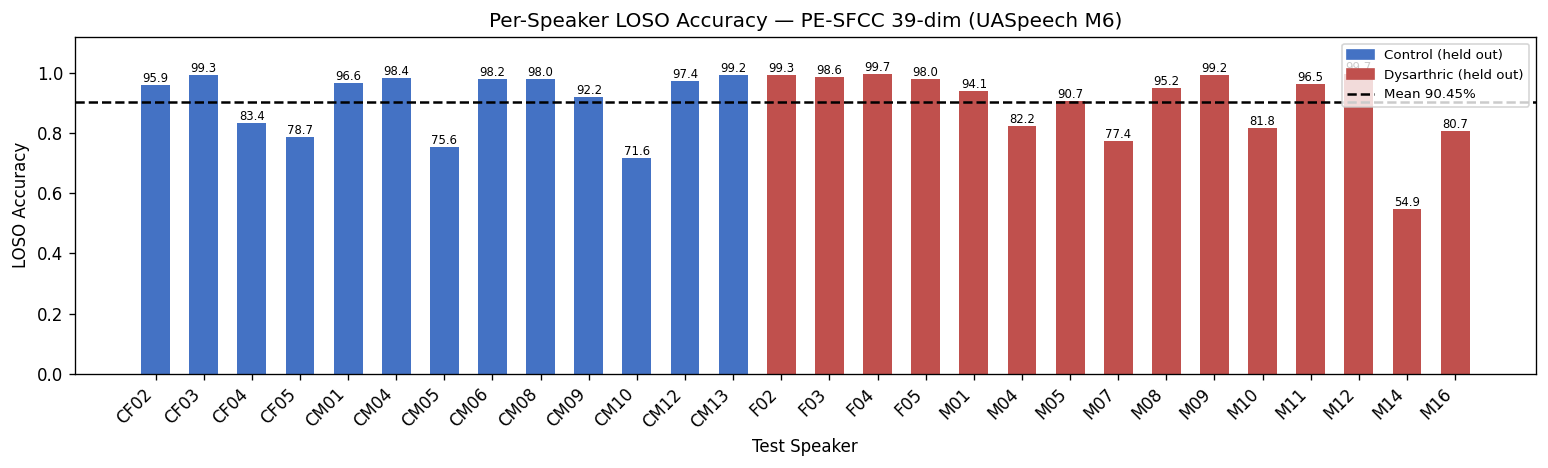

In [8]:
fig, ax = plt.subplots(figsize=(13, 4))
colours = ["#4472C4" if s.startswith("C") else "#C0504D" for s in unique_speakers]
ax.bar(unique_speakers, fold_accs, color=colours, width=0.6)
ax.axhline(fold_accs.mean(), color="black", linestyle="--",
           label=f"Mean {fold_accs.mean()*100:.2f}%")
for i, (spk, acc) in enumerate(zip(unique_speakers, fold_accs)):
    ax.text(i, acc + 0.01, f"{acc*100:.1f}", ha="center", fontsize=7)
ax.set_ylabel("LOSO Accuracy")
ax.set_xlabel("Test Speaker")
ax.set_title("Per-Speaker LOSO Accuracy — PE-SFCC 39-dim (UASpeech M6)")
ax.set_ylim(0, 1.12)
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color="#4472C4", label="Control (held out)"),
    Patch(color="#C0504D", label="Dysarthric (held out)"),
] + ax.get_legend_handles_labels()[0], fontsize=8)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 7.  Confusion Matrix

Row-normalised (each row sums to 100%) — values show recall per class.

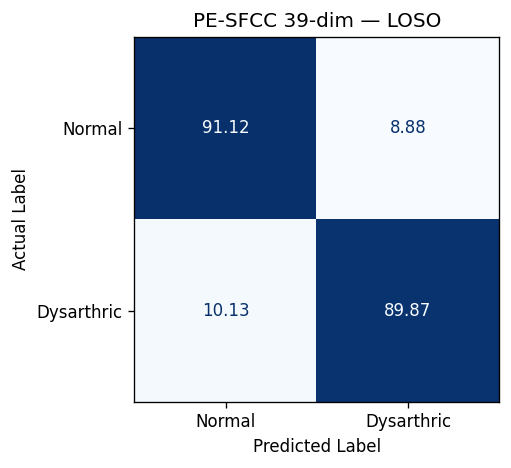

In [9]:
cm = confusion_matrix(all_true, all_pred, normalize="true")
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm * 100, display_labels=["Normal", "Dysarthric"]).plot(
    ax=ax, colorbar=False, cmap="Blues", values_format=".2f"
)
ax.set_title("PE-SFCC 39-dim — LOSO")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
plt.tight_layout()
plt.show()

## 8.  Comparison: MFCC vs wav2vec2-CNN vs PE-SFCC

All three systems evaluated with LOSO RBF-SVM on UASpeech (M6).  
Update `MFCC_ACC` and `W2V_ACC` with the live values from their respective notebooks if needed.

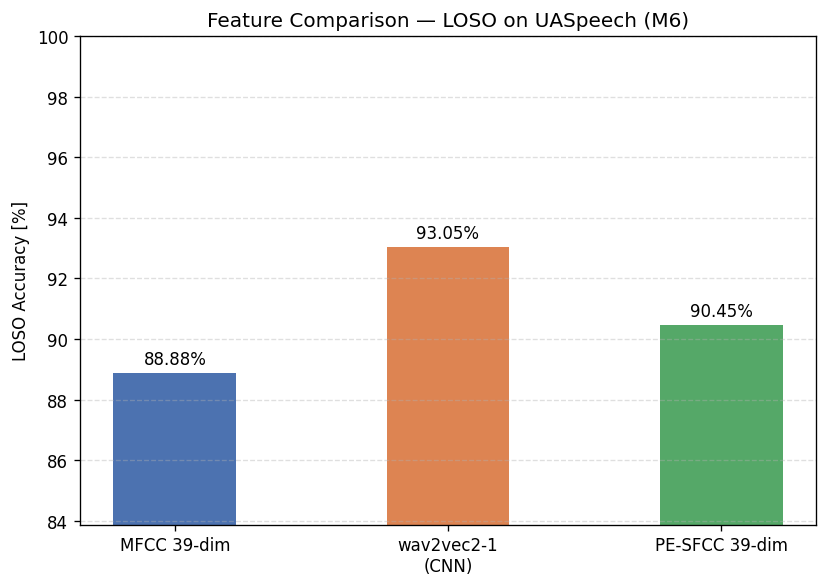

In [10]:
MFCC_ACC = 0.8888   
W2V_ACC  = 0.9305 
PESFCC_ACC = fold_accs.mean()

methods = ["MFCC 39-dim", "wav2vec2-1\n(CNN)", "PE-SFCC 39-dim"]
values  = [MFCC_ACC, W2V_ACC, PESFCC_ACC]
colours = ["#4C72B0", "#DD8452", "#55A868"]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(methods, [v * 100 for v in values], color=colours, width=0.45)
ax.bar_label(bars, labels=[f"{v*100:.2f}%" for v in values], padding=3, fontsize=10)
ax.set_ylabel("LOSO Accuracy [%]")
ax.set_title("Feature Comparison — LOSO on UASpeech (M6)")
bottom = max(min(values) * 100 - 5, 0)
ax.set_ylim(bottom, 100)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()